<a href="https://colab.research.google.com/github/rachakondasaivarshini/GAN-PROGRAMS/blob/main/GAN_exp9_pre_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from IPython.display import display

# Configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EPOCHS = 10
TRAIN_SIZE = 20000
BATCH_SIZE = 128
LATENT_DIM = 100
LEARNING_RATE = 0.0002
SEEDS = [42, 43, 44]
N_EVAL = 2000
N_PROJECTIONS = 128

print("Device:", DEVICE)

if DEVICE.type == "cpu":
    print("For faster training, enable a GPU in Colab.")

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


Device: cpu
For faster training, enable a GPU in Colab.


In [ ]:

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_data = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

subset_rng = torch.Generator().manual_seed(2026)
indices = torch.randperm(
    len(train_data), generator=subset_rng
)[:TRAIN_SIZE]

train_subset = Subset(train_data, indices.tolist())

test_loader = DataLoader(
    test_data, batch_size=N_EVAL, shuffle=False
)

real_eval = next(iter(test_loader))[0].flatten(1)

eval_rng = torch.Generator().manual_seed(1234)

directions = torch.randn(
    784, N_PROJECTIONS, generator=eval_rng
)
directions = directions / directions.norm(
    dim=0, keepdim=True
)

real_projected = torch.sort(
    real_eval @ directions, dim=0
).values

eval_noise = torch.randn(N_EVAL, LATENT_DIM, generator=eval_rng)
display_noise = eval_noise[:64]


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.87MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 155kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.46MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.21MB/s]


In [ ]:

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(LATENT_DIM, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 784),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.net(x)


In [ ]:

@torch.no_grad()
def evaluate(generator):
    generator.eval()
    generated = []

    for noise_batch in eval_noise.split(256):
        generated.append(
            generator(noise_batch.to(DEVICE)).cpu()
        )

    generated = torch.cat(generated).flatten(1)

    fake_projected = torch.sort(
        generated @ directions, dim=0
    ).values

    swd = (
        real_projected - fake_projected
    ).abs().mean().item()

    generator.train()
    return swd


def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


In [ ]:

def train_gan(loss_name, seed):
    set_seed(seed)

    generator = Generator().to(DEVICE)
    discriminator = Discriminator().to(DEVICE)

    optimizer_g = torch.optim.Adam(
        generator.parameters(),
        lr=LEARNING_RATE,
        betas=(0.5, 0.999)
    )

    optimizer_d = torch.optim.Adam(
        discriminator.parameters(),
        lr=LEARNING_RATE,
        betas=(0.5, 0.999)
    )

    criterion = (
        nn.BCEWithLogitsLoss()
        if loss_name == "BCE"
        else nn.MSELoss()
    )

    loader_rng = torch.Generator().manual_seed(seed)
    noise_rng = torch.Generator(device=DEVICE).manual_seed(
        seed + 1000
    )

    loader = DataLoader(
        train_subset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=loader_rng,
        num_workers=0,
        drop_last=True
    )

    history = []
    training_seconds = 0.0

    for epoch in range(1, EPOCHS + 1):
        synchronize()
        start = time.perf_counter()

        g_total = d_total = 0.0
        examples = 0

        for real_images, _ in loader:
            real_images = real_images.to(DEVICE)
            batch_size = real_images.size(0)

            ones = torch.ones(batch_size, 1, device=DEVICE)
            zeros = torch.zeros(batch_size, 1, device=DEVICE)

            # Train discriminator
            optimizer_d.zero_grad(set_to_none=True)

            z = torch.randn(
                batch_size, LATENT_DIM,
                device=DEVICE, generator=noise_rng
            )

            fake_images = generator(z)

            d_real = criterion(
                discriminator(real_images), ones
            )
            d_fake = criterion(
                discriminator(fake_images.detach()), zeros
            )

            d_loss = 0.5 * (d_real + d_fake)
            d_loss.backward()
            optimizer_d.step()

            # Train generator
            for parameter in discriminator.parameters():
                parameter.requires_grad_(False)

            optimizer_g.zero_grad(set_to_none=True)

            z = torch.randn(
                batch_size, LATENT_DIM,
                device=DEVICE, generator=noise_rng
            )

            generated_images = generator(z)
            g_loss = criterion(
                discriminator(generated_images), ones
            )

            if loss_name == "MSE":
                g_loss = 0.5 * g_loss

            g_loss.backward()
            optimizer_g.step()

            for parameter in discriminator.parameters():
                parameter.requires_grad_(True)

            d_total += d_loss.detach().item() * batch_size
            g_total += g_loss.detach().item() * batch_size
            examples += batch_size

        synchronize()
        training_seconds += time.perf_counter() - start
        swd = evaluate(generator)

        row = {
            "Loss": loss_name,
            "Seed": seed,
            "Epoch": epoch,
            "D_loss": d_total / examples,
            "G_loss": g_total / examples,
            "SWD": swd,
            "Training_seconds": training_seconds
        }

        history.append(row)

        print(
            f"{loss_name} | seed={seed} | "
            f"epoch={epoch:02d}/{EPOCHS} | "
            f"D={row['D_loss']:.4f} | "
            f"G={row['G_loss']:.4f} | SWD={swd:.4f}"
        )

    generator.eval()

    with torch.no_grad():
        samples = generator(
            display_noise.to(DEVICE)
        ).cpu()

    return history, samples


In [ ]:

all_history = []
sample_images = {}

for seed in SEEDS:
    for loss_name in ["BCE", "MSE"]:
        history, samples = train_gan(loss_name, seed)
        all_history.extend(history)
        sample_images[(loss_name, seed)] = samples

results = pd.DataFrame(all_history)


BCE | seed=42 | epoch=01/10 | D=0.5417 | G=0.9119 | SWD=0.3931
BCE | seed=42 | epoch=02/10 | D=0.4024 | G=1.4175 | SWD=0.5439
BCE | seed=42 | epoch=03/10 | D=0.3612 | G=1.9268 | SWD=0.3401
BCE | seed=42 | epoch=04/10 | D=0.3826 | G=1.9485 | SWD=0.2873
BCE | seed=42 | epoch=05/10 | D=0.3585 | G=2.2226 | SWD=0.2802
BCE | seed=42 | epoch=06/10 | D=0.3589 | G=2.2514 | SWD=0.2724
BCE | seed=42 | epoch=07/10 | D=0.3327 | G=2.2763 | SWD=0.2223
BCE | seed=42 | epoch=08/10 | D=0.3163 | G=2.5419 | SWD=0.2684
BCE | seed=42 | epoch=09/10 | D=0.2899 | G=2.7273 | SWD=0.2551
BCE | seed=42 | epoch=10/10 | D=0.3428 | G=2.3766 | SWD=0.2649
MSE | seed=42 | epoch=01/10 | D=0.0811 | G=0.4009 | SWD=0.4308
MSE | seed=42 | epoch=02/10 | D=0.0535 | G=0.5350 | SWD=0.4375
MSE | seed=42 | epoch=03/10 | D=0.0449 | G=0.4694 | SWD=0.3592
MSE | seed=42 | epoch=04/10 | D=0.0612 | G=0.4543 | SWD=0.2983
MSE | seed=42 | epoch=05/10 | D=0.0680 | G=0.4055 | SWD=0.2591
MSE | seed=42 | epoch=06/10 | D=0.0853 | G=0.3803 | SWD

In [ ]:

final_results = results[
    results["Epoch"] == EPOCHS
].copy()

summary = final_results.groupby("Loss").agg(
    Mean_final_SWD=("SWD", "mean"),
    SD_final_SWD=("SWD", "std"),
    Mean_training_seconds=("Training_seconds", "mean")
)

print("\nFINAL COMPARISON: lower SWD is better")
display(summary.round(4))

if len(SEEDS) == 1:
    print("Standard deviation is undefined for a single seed.")


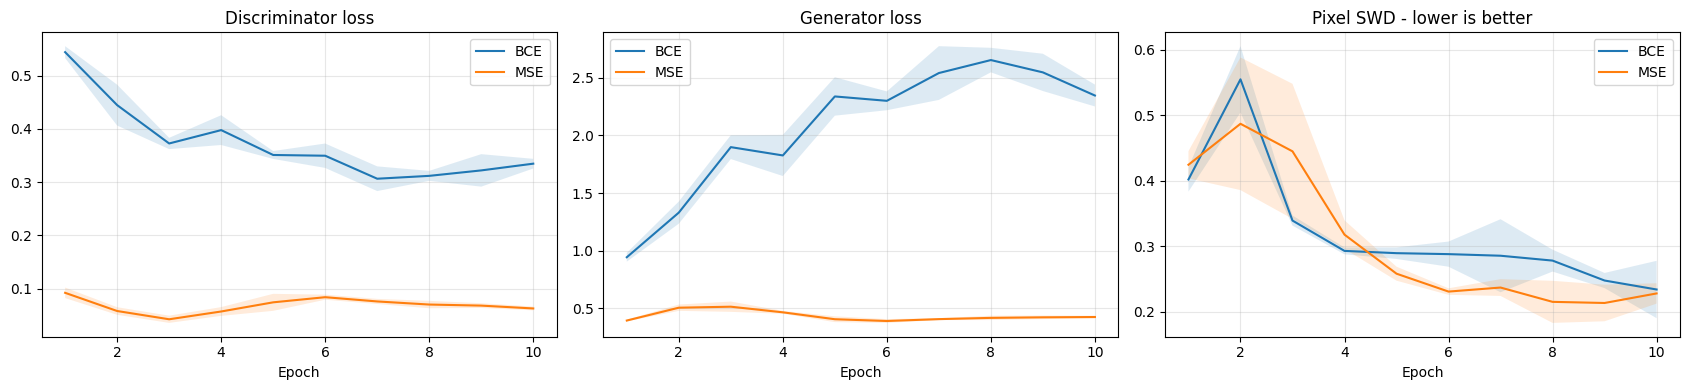

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for loss_name in ["BCE", "MSE"]:
    grouped = (
        results[results["Loss"] == loss_name]
        .groupby("Epoch")[["D_loss", "G_loss", "SWD"]]
    )

    means = grouped.mean()
    stds = grouped.std().fillna(0)

    for axis, metric, title in zip(
        axes,
        ["D_loss", "G_loss", "SWD"],
        [
            "Discriminator loss",
            "Generator loss",
            "Pixel SWD - lower is better"
        ]
    ):
        x = means.index.to_numpy()
        y = means[metric].to_numpy()
        spread = stds[metric].to_numpy()

        axis.plot(x, y, label=loss_name)
        axis.fill_between(
            x, y - spread, y + spread, alpha=0.15
        )
        axis.set_title(title)
        axis.set_xlabel("Epoch")
        axis.grid(alpha=0.3)
        axis.legend()

plt.tight_layout()
plt.show()


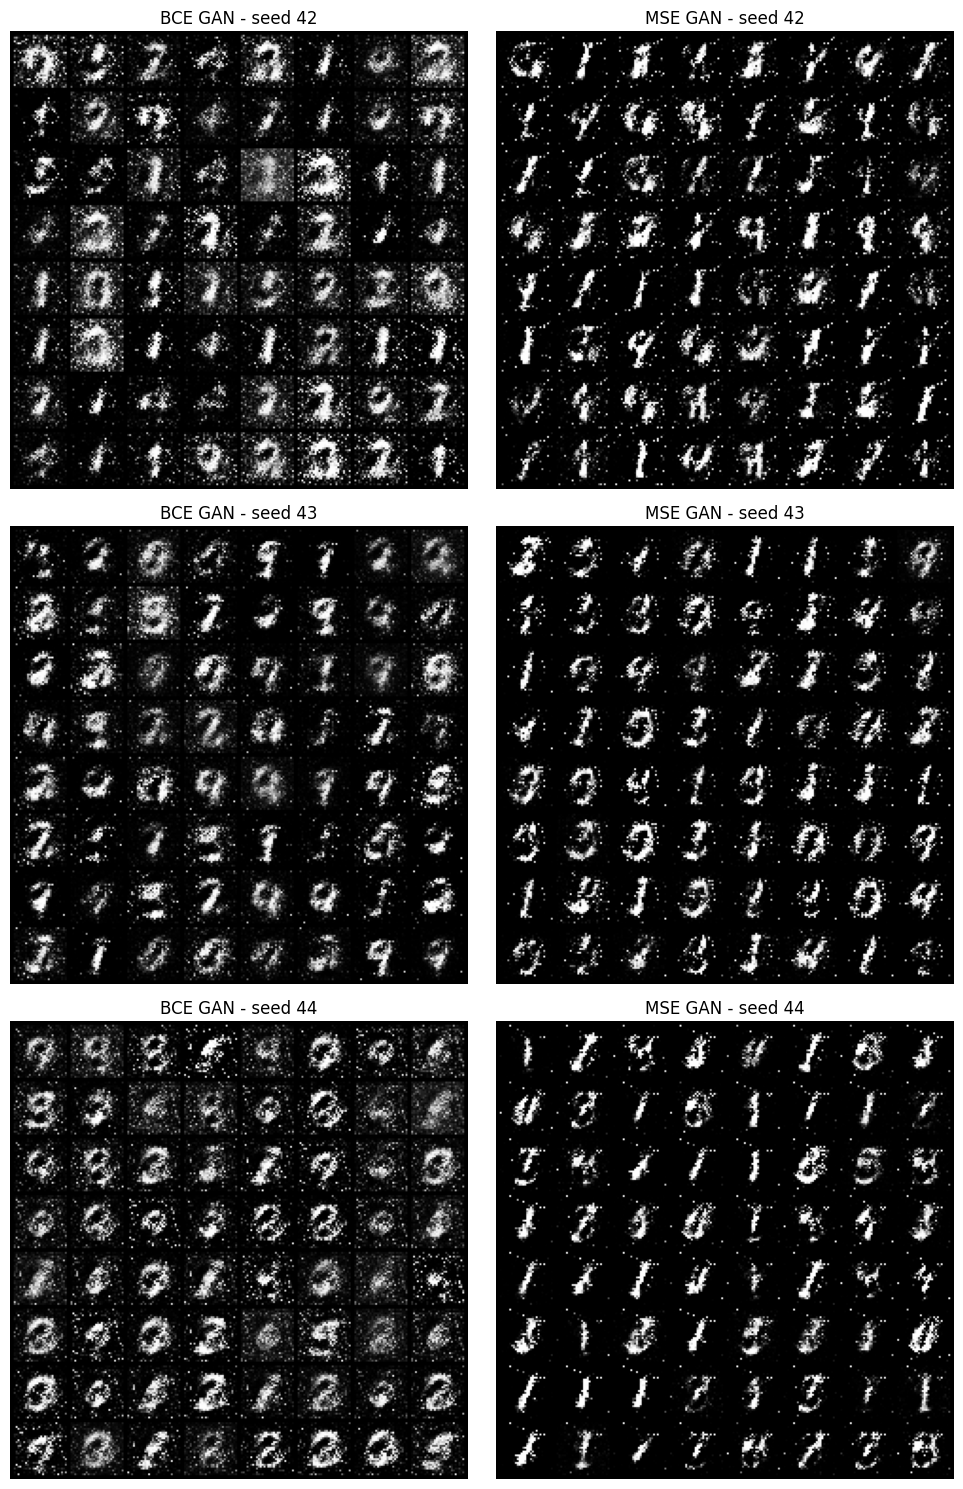

In [ ]:

fig, axes = plt.subplots(
    len(SEEDS), 2,
    figsize=(10, 5 * len(SEEDS)),
    squeeze=False
)

for row, seed in enumerate(SEEDS):
    for col, loss_name in enumerate(["BCE", "MSE"]):
        grid = make_grid(
            sample_images[(loss_name, seed)],
            nrow=8,
            normalize=True,
            value_range=(-1, 1)
        )

        axes[row, col].imshow(
            grid.permute(1, 2, 0).numpy()
        )
        axes[row, col].set_title(
            f"{loss_name} GAN - seed {seed}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()
